### EDA — Tela 2 (base MUPRS: impactos da enchente de 2024 nos municípios do RS)

Análise exploratória da base do **Mapa Único do Plano Rio Grande** **depois da limpeza** (`scripts/limpeza_muprs.ipynb`).

**Fonte:** Mapa Único do Plano Rio Grande (MUP RS), Governo do Estado do RS: https://mup.rs.gov.br/
**Data de coleta:** 23/11/2026 | **Data de referência dos dados:** 03/09/2024

**Entrada:** `dados/processados/muprs_limpo.csv` (uma linha por município). Rodar o notebook de limpeza antes.
**Colunas principais:** `municipio`, `corede`, `situacao`, `pop_atingida`, `pop_total`, `pct_pop_atingida`,
`domicilios_atingidos`, `cad_pessoas_atingidas`, `vpc_auxilios`.

Diferente do INCT, estes números são o que **foi registrado** na enchente de 2024 e não uma simulação. Mesmo
assim, a população atingida é uma estimativa feita pelo governo do estado a partir do Censo 2022 e da área alagada.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
AZUL, CINZA, DESTAQUE = "#2F5D8A", "#8A8F98", "#C98B2B"

def fmt(x):
    return f"{x:,.0f}".replace(",", ".")

milhar = mtick.FuncFormatter(lambda x, _: fmt(x))

df = pd.read_csv("../dados/processados/muprs_limpo.csv", dtype={"codigo_ibge": str})
print(df.shape)
df.head()

(497, 31)


,codigo_ibge,municipio,situacao,corede,pop_atingida,pop_total,domicilios_atingidos,domicilios_total,enderecos_atingidos,enderecos_total,...,vpc_valor_rs,sosrs_auxilios,sosrs_valor_rs,municipio_chave,pct_pop_atingida,pct_domicilios_atingidos,pct_cad_pessoas_atingidas,pct_cnpjs_atingidos,flag,km_atingidos_era_vazio
0,430003,Aceguá,Emergência,Campanha,1,4170,1,2123,2,3075,...,2500.0,0,0.0,ACEGUA,0.02,0.05,0.00,0.00,NaN,False
1,430005,Água Santa,Não Homologado,Nordeste,8,3912,3,1596,5,2268,...,0.0,0,0.0,AGUA SANTA,0.20,0.19,0.32,0.00,não homologado com impacto registrado,False
2,430010,Agudo,Calamidade,Central,1705,16041,873,7368,927,8313,...,550000.0,69,138000.0,AGUDO,10.63,11.85,7.28,2.76,NaN,False
3,430020,Ajuricaba,Emergência,Noroeste Colonial,12,6720,6,2989,7,3597,...,7500.0,0,0.0,AJURICABA,0.18,0.20,0.00,0.00,NaN,False
4,430030,Alecrim,Emergência,Fronteira Noroeste,1,6123,1,3290,2,3864,...,2500.0,0,0.0,ALECRIM,0.02,0.03,0.00,0.00,NaN,False


### Visão geral dos dados

In [2]:
atingidos = df[df.pop_atingida > 0]
print("Municípios do RS:", len(df))
print("Municípios com população atingida:", len(atingidos))
print("Pessoas atingidas:", fmt(df.pop_atingida.sum()),
      f"({df.pop_atingida.sum() / df.pop_total.sum() * 100:.1f}% da população do RS)")
print("Domicílios atingidos:", fmt(df.domicilios_atingidos.sum()))
print("CNPJs atingidos:", fmt(df.cnpjs_atingidos.sum()),
      f"({df.cnpjs_atingidos.sum() / df.cnpjs_total.sum() * 100:.1f}% do total)")
print("Equipamentos públicos atingidos:", fmt(df.equipamentos_atingidos.sum()))
print("Km de estradas atingidos:", fmt(df.km_atingidos.sum()))
print("Auxílios Volta por Cima:", fmt(df.vpc_auxilios.sum()), "| R$", fmt(df.vpc_valor_rs.sum()))
print("Auxílios SOS RS:", fmt(df.sosrs_auxilios.sum()), "| R$", fmt(df.sosrs_valor_rs.sum()))

Municípios do RS: 497
Municípios com população atingida: 360
Pessoas atingidas: 970.790 (8.9% da população do RS)
Domicílios atingidos: 465.024
CNPJs atingidos: 108.296 (9.0% do total)
Equipamentos públicos atingidos: 1.247
Km de estradas atingidos: 11.572
Auxílios Volta por Cima: 100.448 | R$ 251.120.000
Auxílios SOS RS: 36.829 | R$ 73.658.000


### Gráfico 1 — Municípios com mais pessoas atingidas

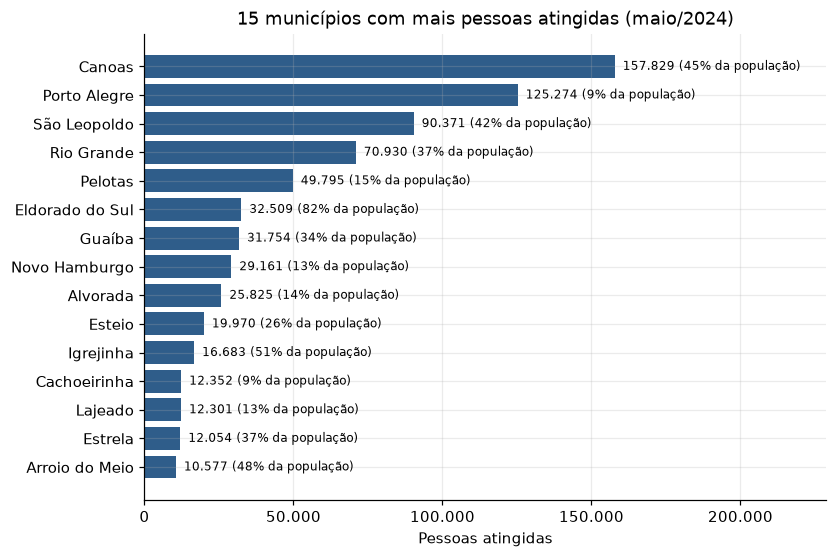

Os 5 primeiros concentram 51% das pessoas atingidas do estado
Os 10 primeiros concentram 65% das pessoas atingidas do estado


In [3]:
top = df.nlargest(15, "pop_atingida").sort_values("pop_atingida")

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.municipio, top.pop_atingida, color=AZUL)
for y, (p, pc) in enumerate(zip(top.pop_atingida, top.pct_pop_atingida)):
    ax.text(p, y, f"  {fmt(p)} ({pc:.0f}% da população)", va="center", fontsize=8)
ax.set_xlim(0, top.pop_atingida.max() * 1.45)
ax.set(xlabel="Pessoas atingidas", title="15 municípios com mais pessoas atingidas (maio/2024)")
ax.xaxis.set_major_formatter(milhar)
plt.show()

for n in (5, 10):
    parte = df.nlargest(n, "pop_atingida").pop_atingida.sum() / df.pop_atingida.sum() * 100
    print(f"Os {n} primeiros concentram {parte:.0f}% das pessoas atingidas do estado")

**Comentário.** O impacto é muito concentrado: os 5 municípios com mais atingidos (Canoas, Porto Alegre, São
Leopoldo, Rio Grande e Pelotas) somam cerca de metade das 970 mil pessoas atingidas do estado, e os 10 primeiros
somam 65%. Canoas lidera com quase 158 mil pessoas, 45% da sua população. Porto Alegre aparece em segundo em
número absoluto (125 mil), mas isso representa só 9% da cidade, porque a capital é muito grande. Assim como na
Tela 1, número absoluto e porcentagem contam histórias diferentes.

### Gráfico 2 — Municípios com maior parte da população atingida

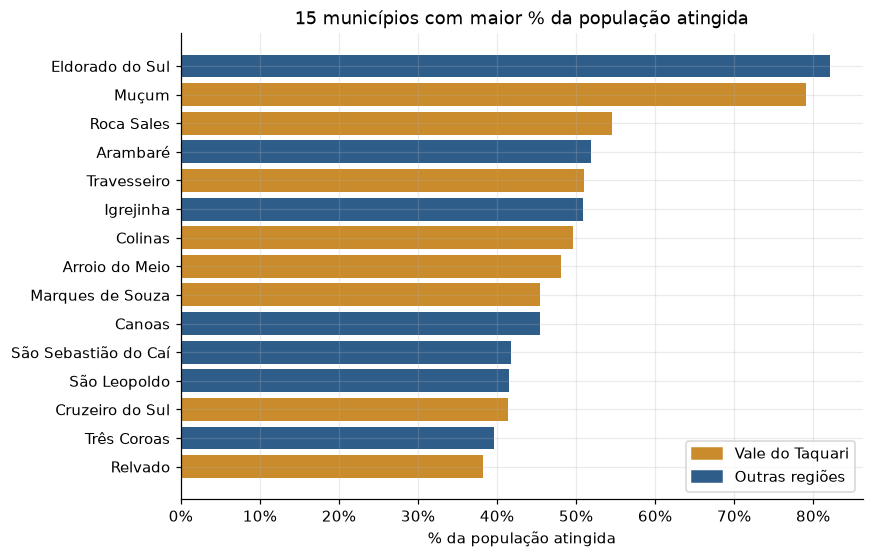

Municípios do Vale do Taquari entre os 15: 8


In [4]:
top_pct = df.nlargest(15, "pct_pop_atingida").sort_values("pct_pop_atingida")
cores = [DESTAQUE if c == "Vale do Taquari" else AZUL for c in top_pct.corede]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top_pct.municipio, top_pct.pct_pop_atingida, color=cores)
ax.set(xlabel="% da população atingida", title="15 municípios com maior % da população atingida")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=DESTAQUE), plt.Rectangle((0, 0), 1, 1, color=AZUL)],
          labels=["Vale do Taquari", "Outras regiões"], loc="lower right")
plt.show()
print("Municípios do Vale do Taquari entre os 15:", (top_pct.corede == "Vale do Taquari").sum())

**Comentário.** Quando o critério é a porcentagem, o ranking muda quase todo. Eldorado do Sul teve 82% da
população atingida e Muçum, 79%. Dos 15 municípios, 8 são do Vale do Taquari, que foi atingido pela cheia do rio
Taquari antes de a água chegar ao Guaíba. São cidades pequenas (Relvado tem menos de 2 mil habitantes), que
quase não aparecem no Gráfico 1, mas onde a enchente atingiu a maior parte da cidade. Por isso a Tela 2 deve
permitir ver os dois critérios.

### Gráfico 3 — Como a porcentagem atingida se distribui entre os municípios

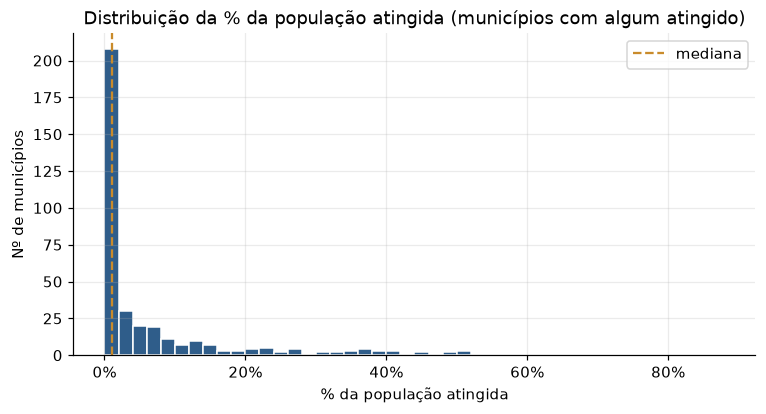

Mediana: 1.06 %
Municípios com menos de 1% atingido: 172 de 360
Municípios com 10% ou mais: 72
Municípios com 50% ou mais: 6


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(atingidos.pct_pop_atingida, bins=range(0, 90, 2), color=AZUL, edgecolor="white")
ax.axvline(atingidos.pct_pop_atingida.median(), color=DESTAQUE, ls="--", label="mediana")
ax.set(xlabel="% da população atingida", ylabel="Nº de municípios",
       title="Distribuição da % da população atingida (municípios com algum atingido)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend()
plt.show()

print("Mediana:", round(atingidos.pct_pop_atingida.median(), 2), "%")
print("Municípios com menos de 1% atingido:", (atingidos.pct_pop_atingida < 1).sum(), "de", len(atingidos))
print("Municípios com 10% ou mais:", (df.pct_pop_atingida >= 10).sum())
print("Municípios com 50% ou mais:", (df.pct_pop_atingida >= 50).sum())

**Comentário.** A distribuição é muito assimétrica. Dos 360 municípios com alguma pessoa atingida, quase metade
(172) teve menos de 1% da população atingida, e a mediana é só 1,1%. Já 72 municípios tiveram 10% ou mais, e 6
passaram de 50%. Ou seja, a enchente afetou quase todo o estado de forma leve e um grupo pequeno de municípios de
forma muito grave. Uma média do estado esconderia isso; no dashboard, é melhor mostrar a distribuição ou o
ranking.

### Gráfico 4 — Impacto por região (COREDE)

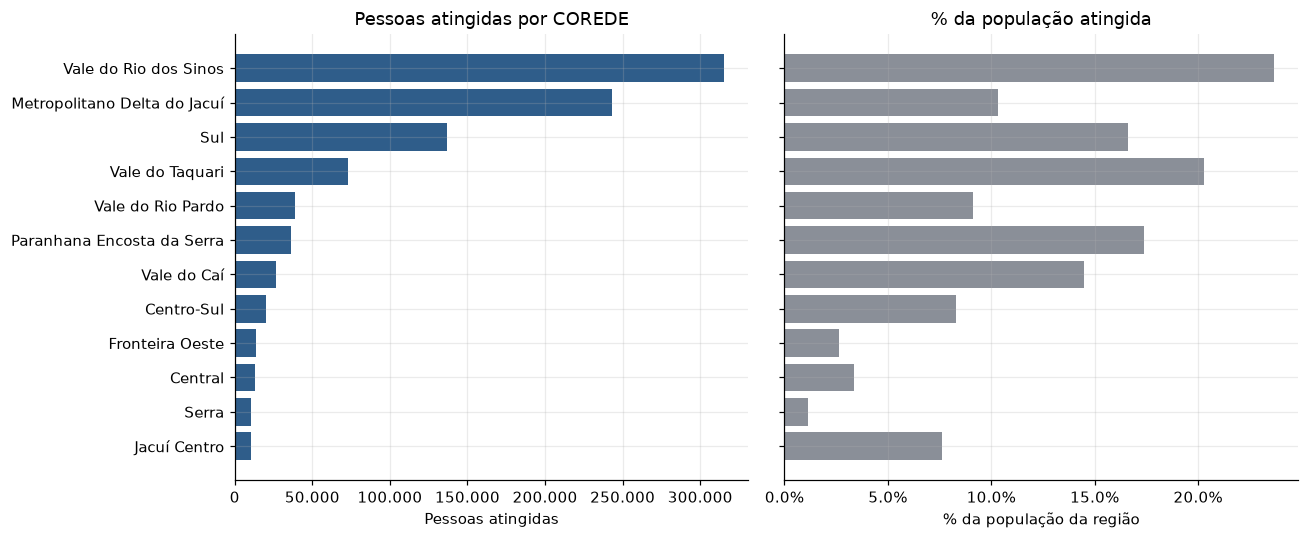

                              pop_atingida  pop_total   pct
corede                                                     
Vale do Rio dos Sinos               315257    1332814  23.7
Metropolitano Delta do Jacuí        243089    2356190  10.3
Sul                                 136855     822462  16.6
Vale do Taquari                      73291     361273  20.3
Vale do Rio Pardo                    38676     424237   9.1
Paranhana Encosta da Serra           36509     209953  17.4
As 4 regiões com mais atingidos somam 79% do total


In [6]:
corede = (df.groupby("corede")
            .agg(pop_atingida=("pop_atingida", "sum"), pop_total=("pop_total", "sum"))
            .assign(pct=lambda x: x.pop_atingida / x.pop_total * 100)
            .sort_values("pop_atingida", ascending=False))
c = corede.head(12).iloc[::-1]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
a1.barh(c.index, c.pop_atingida, color=AZUL)
a1.set(xlabel="Pessoas atingidas", title="Pessoas atingidas por COREDE")
a1.xaxis.set_major_formatter(milhar)
a2.barh(c.index, c.pct, color=CINZA)
a2.set(xlabel="% da população da região", title="% da população atingida")
a2.xaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout(); plt.show()

quatro = corede.head(4).pop_atingida.sum() / corede.pop_atingida.sum() * 100
print(corede.head(6).round(1))
print(f"As 4 regiões com mais atingidos somam {quatro:.0f}% do total")

**Comentário.** As regiões banhadas pelos rios que formam o Guaíba e pela Lagoa dos Patos concentram o impacto.
Vale do Rio dos Sinos (315 mil pessoas, 24% da região), Metropolitano Delta do Jacuí (243 mil, onde está Porto
Alegre), Sul (137 mil, com Pelotas e Rio Grande) e Vale do Taquari (73 mil) somam cerca de 80% dos atingidos. O
Vale do Taquari tem menos pessoas atingidas que as outras três, mas uma das maiores porcentagens (20%). Regiões
como Serra, Missões e Campanha ficaram abaixo de 2%.

### Gráfico 5 — Situação do município: emergência, calamidade ou não homologado

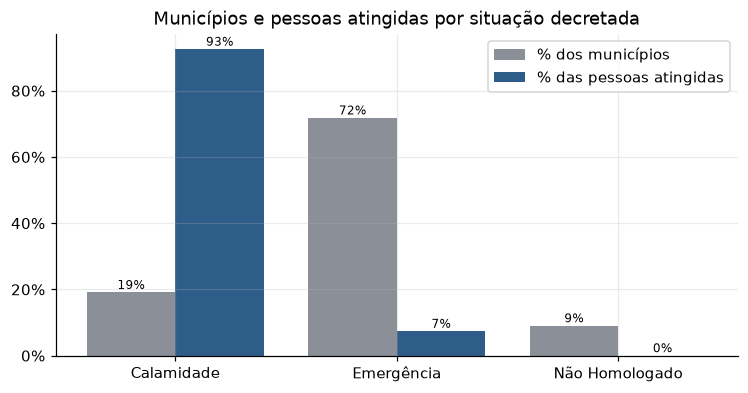

                municipios  pop_atingida  mediana_pct
situacao                                             
Calamidade              95        898707        13.71
Emergência             357         71773         0.15
Não Homologado          45           310         0.00


In [7]:
situacao = df.groupby("situacao").agg(municipios=("municipio", "size"), pop_atingida=("pop_atingida", "sum"))
situacao = situacao.loc[["Calamidade", "Emergência", "Não Homologado"]]
pct = situacao / situacao.sum() * 100

fig, ax = plt.subplots(figsize=(8, 3.8))
x = range(len(pct))
ax.bar([i - 0.2 for i in x], pct.municipios, width=0.4, color=CINZA, label="% dos municípios")
ax.bar([i + 0.2 for i in x], pct.pop_atingida, width=0.4, color=AZUL, label="% das pessoas atingidas")
for i, (m, p) in enumerate(zip(pct.municipios, pct.pop_atingida)):
    ax.text(i - 0.2, m + 1, f"{m:.0f}%", ha="center", fontsize=8)
    ax.text(i + 0.2, p + 1, f"{p:.0f}%", ha="center", fontsize=8)
ax.set_xticks(list(x)); ax.set_xticklabels(pct.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set(title="Municípios e pessoas atingidas por situação decretada")
ax.legend()
plt.show()

print(situacao.assign(mediana_pct=df.groupby("situacao").pct_pop_atingida.median()).round(2))

**Comentário.** Os 95 municípios em **calamidade pública** são só 19% dos municípios, mas concentram 93% das
pessoas atingidas, e a mediana deles é de 14% da população atingida. Os 357 em **emergência** são a maioria (72%)
e somam só 7% dos atingidos, com mediana de 0,15%. Os 45 **não homologados** somam apenas 310 pessoas. A
classificação oficial, portanto, acompanha bem a gravidade medida nos dados, e pode ser usada como filtro na
Tela 2.

### Gráfico 6 — As famílias mais pobres foram mais atingidas?

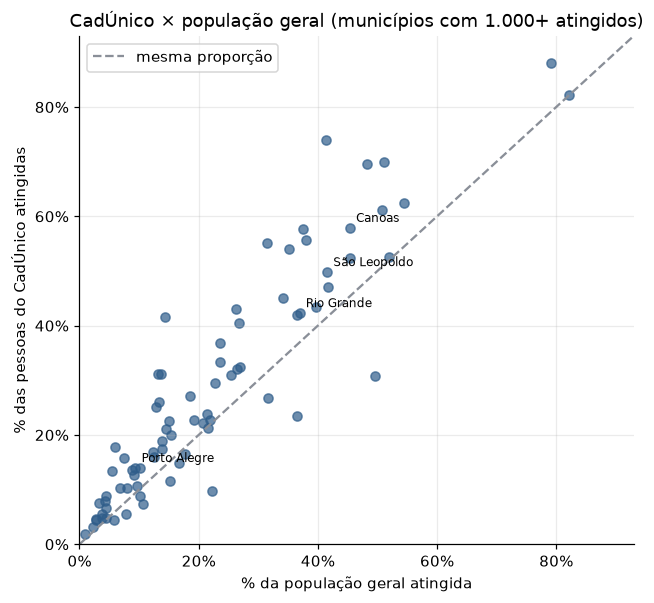

66 de 78 municípios ficam acima da linha (CadÚnico mais atingido)
RS: 12.5% do CadÚnico atingido x 8.9% da população geral
Pessoas do CadÚnico: 33% da população, mas 46% dos atingidos


In [8]:
base = df[df.pop_atingida >= 1000]

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(base.pct_pop_atingida, base.pct_cad_pessoas_atingidas, color=AZUL, alpha=.7)
limite = max(base.pct_pop_atingida.max(), base.pct_cad_pessoas_atingidas.max()) + 5
ax.plot([0, limite], [0, limite], color=CINZA, ls="--", label="mesma proporção")
for _, l in base.nlargest(4, "pop_atingida").iterrows():
    ax.annotate(l.municipio, (l.pct_pop_atingida, l.pct_cad_pessoas_atingidas), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
ax.set(xlabel="% da população geral atingida", ylabel="% das pessoas do CadÚnico atingidas",
       title="CadÚnico × população geral (municípios com 1.000+ atingidos)", xlim=(0, limite), ylim=(0, limite))
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend()
plt.show()

acima = (base.pct_cad_pessoas_atingidas > base.pct_pop_atingida).sum()
print(f"{acima} de {len(base)} municípios ficam acima da linha (CadÚnico mais atingido)")
t = df.sum(numeric_only=True)
print(f"RS: {t.cad_pessoas_atingidas / t.cad_pessoas_total * 100:.1f}% do CadÚnico atingido x "
      f"{t.pop_atingida / t.pop_total * 100:.1f}% da população geral")
print(f"Pessoas do CadÚnico: {t.cad_pessoas_total / t.pop_total * 100:.0f}% da população, mas "
      f"{t.cad_pessoas_atingidas / t.pop_atingida * 100:.0f}% dos atingidos")

**Comentário.** O CadÚnico reúne as famílias de baixa renda. Em 66 dos 78 municípios com mais de mil atingidos, a
porcentagem do CadÚnico atingida é **maior** que a da população geral (pontos acima da linha tracejada). No estado,
12,5% das pessoas do CadÚnico foram atingidas, contra 8,9% da população geral. Isso indica que as famílias mais
pobres foram proporcionalmente mais atingidas, provavelmente porque moram mais em áreas baixas e próximas aos rios.
**Cuidado:** as duas porcentagens vêm de cadastros diferentes (CadÚnico e Censo), então a comparação é um
indício, não uma prova. Essa pergunta é um dos exemplos do enunciado para a Tela 2.

### Gráfico 7 — Auxílio Volta por Cima nos municípios mais atingidos

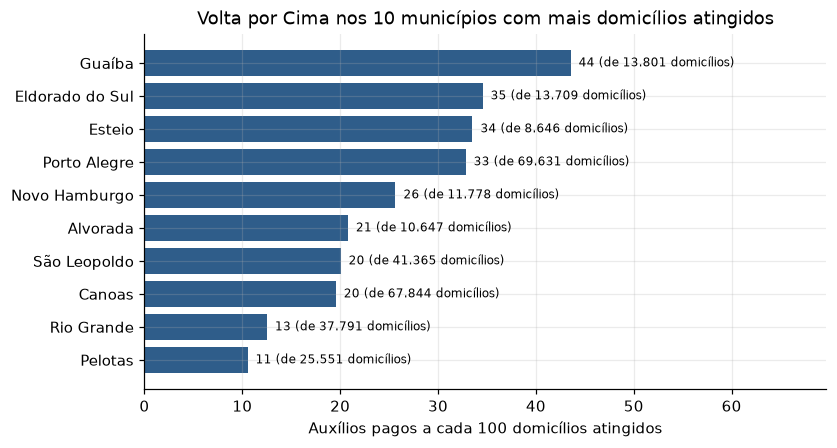

Mediana (municípios com 100+ domicílios atingidos): 12.1
Municípios com mais auxílios do que domicílios atingidos: 5


In [9]:
grandes = (df.nlargest(10, "domicilios_atingidos")
             .assign(aux_por_100=lambda x: x.vpc_auxilios / x.domicilios_atingidos * 100)
             .sort_values("aux_por_100"))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(grandes.municipio, grandes.aux_por_100, color=AZUL)
for y, (v, d) in enumerate(zip(grandes.aux_por_100, grandes.domicilios_atingidos)):
    ax.text(v, y, f"  {v:.0f} (de {fmt(d)} domicílios)", va="center", fontsize=8)
ax.set_xlim(0, grandes.aux_por_100.max() * 1.6)
ax.set(xlabel="Auxílios pagos a cada 100 domicílios atingidos",
       title="Volta por Cima nos 10 municípios com mais domicílios atingidos")
plt.show()

todos = df[df.domicilios_atingidos >= 100].assign(aux_por_100=lambda x: x.vpc_auxilios / x.domicilios_atingidos * 100)
print("Mediana (municípios com 100+ domicílios atingidos):", round(todos.aux_por_100.median(), 1))
print("Municípios com mais auxílios do que domicílios atingidos:", (todos.aux_por_100 > 100).sum())

**Comentário.** O *Volta por Cima* pagou R$ 2.500 por família atingida. Entre os 10 municípios com mais domicílios
atingidos, a cobertura varia bastante: Guaíba recebeu 44 auxílios a cada 100 domicílios atingidos e Porto Alegre,
33, enquanto Pelotas e Rio Grande ficaram entre 11 e 13. O programa tinha critérios de renda (CadÚnico), então
não se espera 100%, mas a diferença entre municípios parecidos sugere desigualdade no acesso ao auxílio. Alguns
municípios pequenos têm **mais** auxílios que domicílios atingidos, o que indica que a estimativa de domicílios
atingidos pode estar subestimada ali. Os dados são de setembro/2024 e os pagamentos podem ter continuado depois.

### Gráfico 8 — Porto Alegre: o que foi registrado × a simulação do INCT (ligação com a Tela 1)

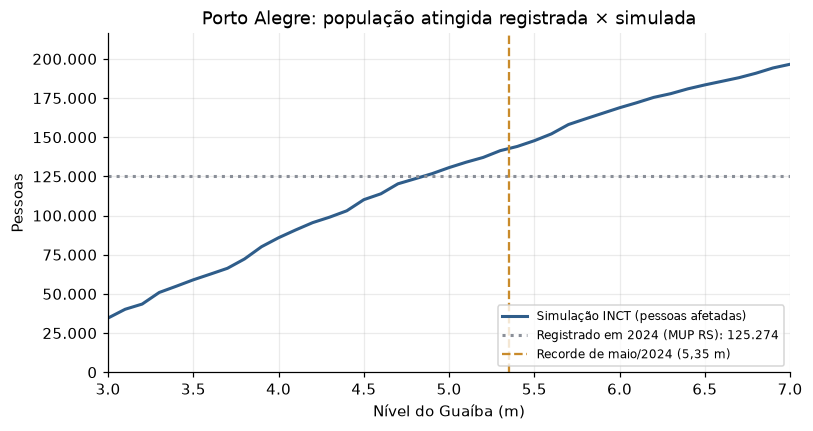

Simulação a 5.3 m: 141.435 (+13% em relação ao registrado)
Simulação a 5.4 m: 144.129 (+15% em relação ao registrado)
Primeiro nível em que a simulação passa do registrado: 4.9 m


In [10]:
raw = json.load(open("../dados/processados/data_alterado.json", encoding="utf-8"))
if isinstance(raw, list):
    inct = pd.DataFrame(raw)
else:
    inct = pd.DataFrame([{"nivel_m": float(n.removesuffix("m").replace("_", ".")), "bairro": b, **v}
                         for n, bs in raw.items() for b, v in bs.items()])
curva = inct.groupby("nivel_m").affected_population.sum()
observado = df.loc[df.municipio == "Porto Alegre", "pop_atingida"].iloc[0]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curva.index, curva, color=AZUL, lw=2, label="Simulação INCT (pessoas afetadas)")
ax.axhline(observado, color=CINZA, ls=":", lw=2, label=f"Registrado em 2024 (MUP RS): {fmt(observado)}")
ax.axvline(5.35, color=DESTAQUE, ls="--", label="Recorde de maio/2024 (5,35 m)")
ax.set(xlabel="Nível do Guaíba (m)", ylabel="Pessoas", xlim=(3, 7), ylim=(0, curva.loc[7.0] * 1.1),
       title="Porto Alegre: população atingida registrada × simulada")
ax.yaxis.set_major_formatter(milhar)
ax.legend(fontsize=8, loc="lower right")
plt.show()

for n in (5.3, 5.4):
    print(f"Simulação a {n} m: {fmt(curva.loc[n])} ({(curva.loc[n] / observado - 1) * 100:+.0f}% em relação ao registrado)")
print("Primeiro nível em que a simulação passa do registrado:", curva[curva >= observado].index.min(), "m")

**Comentário.** Este gráfico liga as duas telas. Em maio de 2024 o Guaíba chegou a 5,35 m e o MUP RS registrou
125 mil pessoas atingidas em Porto Alegre. A simulação do INCT, entre 5,3 e 5,4 m, estima um pouco mais, de 10% a
15% acima do registrado (o valor exato aparece na saída acima), e alcança o valor registrado por volta de 4,9 a 5,0 m. As duas fontes usam métodos
diferentes (a simulação supõe que todos os prédios abaixo da cota alagam e que as pessoas se distribuem igualmente
entre eles; o MUP RS cruza a mancha observada com o Censo), mas chegam à **mesma ordem de grandeza**, o que dá
confiança à simulação da Tela 1. A diferença também pode refletir os diques e comportas que seguraram parte da
água em alguns bairros.

### Resumo: o que levar para a Tela 2

- **Ranking de municípios** com a escolha entre número de pessoas e % da população (Gráficos 1 e 2).
- **Filtro por região (COREDE) e por situação decretada** (Gráficos 4 e 5).
- **CadÚnico × população geral**, que responde se os mais pobres foram mais atingidos (Gráfico 6).
- **Porto Alegre registrado × simulado**, a visualização que conversa com a Tela 1 (Gráfico 8).

**Limitações para o aviso da Tela 2:** os dados são de 03/09/2024; a população atingida é uma estimativa do
governo do estado a partir do Censo 2022; a base é por município, então não pode ser cruzada com os bairros da
Tela 1; e 36 municípios têm valores marcados como suspeitos na limpeza (`muprs_inconsistencias.csv`).